# Utilities

## Libraries

In [49]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
import re, string, joblib, umap, time, pickle
import numpy as np
from collections import Counter

# Natural language processing
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

# Data science
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN

# Visualization
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px

# Hierarchical clustering
from fastcluster import linkage
from scipy.cluster.hierarchy import dendrogram, fcluster
from scipy.spatial.distance import pdist

# Words cloud
from wordcloud import WordCloud

## Functions

In [50]:
# Text preprocessing
def preprocess_text(text, words2remove):
    text = text.lower()                                                  # Lower case
    text = re.sub(r'[^a-z\s]', ' ', text)                                # Remove numbers and special characteres
    # split(r'\s+') is the same as word_tokenize()
    # if the text doesn´t have special characters
    # text = text.split(r'\s+')                                          # Remove multiple spaces, convert to list
    tokens = word_tokenize(text)                                         # Tokenization
    tokens = [word for word in tokens if word not in stop_words]         # Remove stopwords
    tokens = [word for word in tokens if word not in string.punctuation] # Remove punctuation
    tokens = [word for word in tokens if word not in words2remove]       # Remove words from custom list
    tokens = [lemmatizer.lemmatize(word) for word in tokens]             # Lemmatization
    return ' '.join(tokens)

# Word clouds for given string
def word_cloud(text):
    w = 10
    h = 5
    word_freq = Counter(text.split(' '))
    wordcloud = WordCloud(width=w * 100, height=h * 100,
                           background_color='white',
                           stopwords=None,
                           min_font_size=10).generate_from_frequencies(word_freq)
    plt.figure(figsize=(w, h), facecolor=None)
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.tight_layout(pad=0)
    plt.show()

# Load data

In [51]:
data = pd.read_csv('../data/input/api/data_filtered.csv')
data.shape

(500, 7)

In [52]:
df = pd.read_csv('../data/input/api/data_cleaned.csv')
df.shape

(500, 4)

In [53]:
df_vectorized = pd.read_csv('../data/output/df_vectorized.csv')
X = df_vectorized.values
X.shape

(500, 3354)

In [54]:
words2remove = []

In [55]:
vectorizer = joblib.load('../models/vectorizer.pkl')
words = vectorizer.get_feature_names_out()

Dimensionality reduction

Keep 95% of explained variance

In [56]:
# explained_variance_ratio_goal = 0.8
# pca = PCA(n_components=explained_variance_ratio_goal)
# pca.fit(df_vectorized)
# n_components = pca.n_components_
# n_components

In [57]:
X_original = X.copy()
df_vectorized_original = df_vectorized.copy()

# # X = PCA(n_components=n_components).fit_transform(X) # Specify number of components
# X = pca.transform(X) # Use fitted PCA with 95% of explained variance
# df_vectorized = pd.DataFrame(X)

# # Normalize
# X = X / np.linalg.norm(X, axis=1, keepdims=True)
# df_vectorized = pd.DataFrame(X)

In [58]:
X_original.shape

(500, 3354)

# KNN search

In [59]:
n_neighbors = 50

knn = NearestNeighbors(n_neighbors=n_neighbors, metric='cosine', algorithm='brute').fit(X)

# Query text

# query_text = "physics informed reinforcement learning"
query_text = "Artificial intelligence, deep learning, imitation learning, reinforcement learning, and neural networks in power converters."
# query_text = "Control strategy, closed loop, nested control, submodules, capacitor voltage, circulating currents, common-mode voltage, current control, model predictive control, proportional-integral controller, modeling, total cluster and intercluster capacitor energy balancing, low-frequency oscillation mitigation."
print(query_text)

# Preprocessing
query_text = [preprocess_text(query_text, words2remove)]
print(query_text)

# Vectorize
query_text_vec = vectorizer.transform(query_text).toarray()

# Dimensionality reduction
# query_text_vec = pca.transform(query_text_vec)

print(query_text_vec)

# Calculate KNNs
knn_distances, knn_idxs = knn.kneighbors(query_text_vec.reshape(1, -1))

for i, knn_idx in enumerate(knn_idxs[0]):
    display(f"Neighbor {i+1}, Index: {knn_idx}, Title: {data['title'][knn_idx]}")
    display(f"Abstract {data['html_url'][knn_idx]}: {data['abstract'][knn_idx]}")

Artificial intelligence, deep learning, imitation learning, reinforcement learning, and neural networks in power converters.
['artificial intelligence deep learning imitation learning reinforcement learning neural network power converter']
[[0. 0. 0. ... 0. 0. 0.]]


'Neighbor 1, Index: 387, Title: detailed modelling and control of a modular multilevel converter with full bridge submodules in a multi terminal high voltage dc network'

'Abstract https://ieeexplore.ieee.org/document/9209766/: presently there is a rising interest towards multiterminal high voltage direct current networks which use multilevel converters furthermore even though full bridge submodule topologies have some advantages over half bridge there is less research regarding simulation and control of multiterminal networks with such topology the goal of this paper is to bring forward a detailed modelling method for modular multilevel converters which use full bridge submodules in the context of multiterminal networks moreover great attention is given to the process of converter controller tuning the simulation and control method are demonstrated using matlab simulink'

'Neighbor 2, Index: 487, Title: model free sequential predictive control for mmc with variable candidate set'

'Abstract https://ieeexplore.ieee.org/document/9625956/: this article proposes a model free sequential predictive control method for an active front end modular multilevel converter afe mmc in this approach a generalized ultra local model of modular multilevel converter mmc including grid side powers and three phase circulating currents is first established based on this a predictor based neural network pnn is deployed to estimate the unmodeled dynamics and perturbations of the mmc which avoids the use of model parameters leading to improved robustness performance meanwhile a sequential predictive control with variable candidate set is proposed in this design to eliminate the weighting factors in the control process while remaining the flexible control of grid side powers and circulating currents in mmc finally neither the knowledge of mathematical models nor the identification of weighting factors is required in this proposal resulting in enhanced performance and less tuning work unde

...

'Abstract https://ieeexplore.ieee.org/document/7281622/: the modular multilevel converter mmc even though a fairly recent converter is considered a very important one for the future of electrical power systems variable speed drives and other applications the mmc enables ac dc and dc ac conversion at virtually any voltage levels without relying on bulky transformers this work presents a newly developed comprehensive control oriented model and a control strategy implementation that focuses on rectifier applications for medium voltage drives and is naturally derived from the presented model in addition a survey on existing mmc control strategies is presented'

'Neighbor 49, Index: 185, Title: decoupled current model and control of modular multilevel converters'

'Abstract https://ieeexplore.ieee.org/document/7047221/: modular multilevel converters offer several benefits such as high scalability and power quality which are particularly advantageous for high voltage dc transmission systems however the control of such converters is very challenging due to the number of control objectives to be achieved simultaneously the input and output currents must be controlled at their own references and these references must be properly generated in order to keep the average capacitor voltage constant the circulating current can be controlled either to minimize losses or to reduce capacitor voltage ripple additionally the capacitor voltage must be kept balanced among cells during the converter operation in this paper a model with four independent dynamical components of the arm currents which also considers the effect of ac and dc systems is proposed the proposed model facilitates the dynamical analysis of currents and simplifies the design and implementati

'Neighbor 50, Index: 307, Title: an improved control system for modular multilevel converters featuring new modulation strategy and voltage balancing control'

'Abstract https://ieeexplore.ieee.org/document/6647231/: modular multilevel converter becomes one of the most promising high power converters thanks to their modular structure design distributed dc capacitors improved power quality and no separate dc voltage sources required however capacitor voltage balancing remains one major challenge this paper proposes a new voltage balancing control associated with an improved pulsewidth modulation pwm method specifically a new mathematical model and control structure with multi loops including a new balancing control loop between the upper and lower arms are presented the capacitor voltages can be well balanced without adding unnecessary switching to any sms and voltage sorting algorithm moreover the control and modulation are more accurate and the ac power quality can be improved simulations and experimental results have verified the effectiveness of proposed methods'

In [60]:
# import json

# # Save the index to a JSON file
# with open('../data/output/knn_indices.json', 'w') as f:
#     json.dump(knn_idxs[0].tolist(), f)

# Dimensionality reduction

### PCA

In [61]:
# # PCA 2D
# X_pca_2d = PCA(n_components=2).fit_transform(df_vectorized)
# df['pca2d_1'] = X_pca_2d[:, 0]
# df['pca2d_2'] = X_pca_2d[:, 1]

# # PCA 3D
# X_pca_3d = PCA(n_components=3).fit_transform(df_vectorized)
# df['pca3d_1'] = X_pca_3d[:, 0]
# df['pca3d_2'] = X_pca_3d[:, 1]
# df['pca3d_3'] = X_pca_3d[:, 2]

# # Graficar
# colors = np.ones(len(df))  # Color base
# colors_knn = np.zeros(len(df))  # Color para los KNN
# colors_knn[knn_idxs[0]] = 1  # Resaltar los KNN

# fig = make_subplots(rows=1, cols=2, subplot_titles=("PCA 2D", "PCA 3D"), 
#                     specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# # Puntos normales (fondo)
# fig.add_trace(
#     go.Scatter(x=df['pca2d_1'], y=df['pca2d_2'], mode='markers',
#                marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
#                text=data['title'],
#                hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
#     row=1, col=1)

# # Puntos resaltados (delante)
# fig.add_trace(
#     go.Scatter(x=df.loc[knn_idxs[0], 'pca2d_1'], 
#                y=df.loc[knn_idxs[0], 'pca2d_2'], 
#                mode='markers',
#                marker=dict(color='red', size=5, opacity=1), 
#                text=data.loc[knn_idxs[0], 'title'], 
#                hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
#     row=1, col=1)

# # Puntos normales en 3D (fondo)
# fig.add_trace(
#     go.Scatter3d(x=df['pca3d_1'], y=df['pca3d_2'], z=df['pca3d_3'], mode='markers',
#                  marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
#                  text=data['title'],
#                  hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
#     row=1, col=2)

# # Puntos resaltados en 3D (delante)
# fig.add_trace(
#     go.Scatter3d(x=df.loc[knn_idxs[0], 'pca3d_1'], 
#                  y=df.loc[knn_idxs[0], 'pca3d_2'], 
#                  z=df.loc[knn_idxs[0], 'pca3d_3'], 
#                  mode='markers',
#                  marker=dict(color='red', size=5, opacity=1), 
#                  text=data.loc[knn_idxs[0], 'title'], 
#                  hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
#     row=1, col=2)

# fig.update_layout(height=600, width=1200, title_text="PCA 2D y 3D", showlegend=False)
# fig.show()

### UMAP

In [62]:
# n_neighbors = 200
# n_neighbors = int(len(df) / k)

# n_neighbors = 200
n_neighbors = 50 # 6.5x minutos, resultado: vision mas global, no se distinguen tanto los clusters
# n_neighbors = 20 # 2.5x minutos, resultado: no se distinguen los clusters
# n_neighbors = 10 # 1.5x minutos, resultado: puntos muy juntos, se distinguen los clusters
n_neighbors = 5 # x minutos, resultado: se distinguen bien los clusters, se ven un poco desconectados

min_dist = 0

# UMAP 2D
reducer_2d = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=2, random_state=0, metric='cosine')
embedding_2d = reducer_2d.fit_transform(df_vectorized)
df['umap2d_1'] = embedding_2d[:, 0]
df['umap2d_2'] = embedding_2d[:, 1]

# UMAP 3D
reducer_3d = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=3, random_state=0, metric='cosine')
embedding_3d = reducer_3d.fit_transform(df_vectorized)
df['umap3d_1'] = embedding_3d[:, 0]
df['umap3d_2'] = embedding_3d[:, 1]
df['umap3d_3'] = embedding_3d[:, 2]

# Graficar
colors = np.ones(len(df))  # Color base
colors_knn = np.zeros(len(df))  # Color para los KNN
colors_knn[knn_idxs[0]] = 1  # Resaltar los KNN

fig = make_subplots(rows=1, cols=2, subplot_titles=("UMAP 2D", "UMAP 3D"), 
                    specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# Puntos normales (fondo)
fig.add_trace(
    go.Scatter(x=df['umap2d_1'], y=df['umap2d_2'], mode='markers',
               marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
               text=data['title'],
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos resaltados (delante)
fig.add_trace(
    go.Scatter(x=df.loc[knn_idxs[0], 'umap2d_1'], 
               y=df.loc[knn_idxs[0], 'umap2d_2'], 
               mode='markers',
               marker=dict(color='red', size=5, opacity=1), 
               text=data.loc[knn_idxs[0], 'title'], 
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos normales en 3D (fondo)
fig.add_trace(
    go.Scatter3d(x=df['umap3d_1'], y=df['umap3d_2'], z=df['umap3d_3'], mode='markers',
                 marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
                 text=data['title'],
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Puntos resaltados en 3D (delante)
fig.add_trace(
    go.Scatter3d(x=df.loc[knn_idxs[0], 'umap3d_1'],
                 y=df.loc[knn_idxs[0], 'umap3d_2'],
                 z=df.loc[knn_idxs[0], 'umap3d_3'],
                 mode='markers',
                 marker=dict(color='red', size=5, opacity=1), 
                 text=data.loc[knn_idxs[0], 'title'], 
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

fig.update_layout(height=600, width=1200, title_text="UMAP 2D y 3D", showlegend=False)
fig.show()

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



## Plot KNN

In [63]:
reduced_zero = reducer_2d.transform(np.zeros(df_vectorized.shape[1]).reshape(1, -1))
reduced_knn = reducer_2d.transform(df_vectorized.iloc[knn_idxs[0]])
reduced_query = reducer_2d.transform(query_text_vec)

knn_distances = knn_distances.flatten()
reduced_knn.shape, reduced_query.shape, knn_distances.shape, reduced_zero

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



((50, 2), (1, 2), (50,), array([[6.5497985, 9.555233 ]], dtype=float32))

In [64]:
knn_distances = knn_distances[::-1]

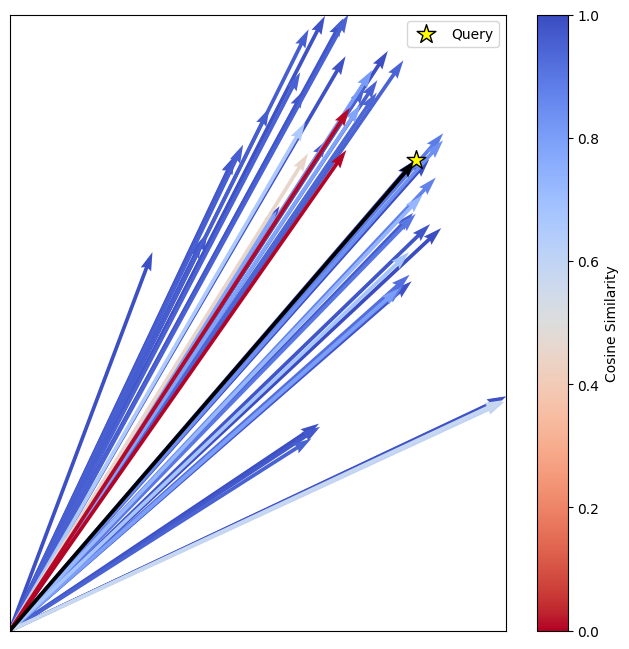

In [65]:
# Asegúrate de que las distancias estén normalizadas entre 0 y 1
exp = 1
knn_distances_normalized = (knn_distances**exp - min(knn_distances**exp)) / (max(knn_distances**exp) - min(knn_distances**exp))

# Graficar
plt.figure(figsize=(8, 8))

# Crear un mapa de colores para las distancias normalizadas
norm = plt.Normalize(vmin=0, vmax=1)  # Normalización de las distancias
sm = plt.cm.ScalarMappable(cmap="coolwarm_r", norm=norm)  # Invertir el colormap con "coolwarm_r"
sm.set_array([])  # Necesario para que la barra de colores funcione

# 2. Graficar los vectores de los vecinos más cercanos (KNN)
for i in range(reduced_knn.shape[0]):
    knn_point = reduced_knn[i]
    color = sm.to_rgba(knn_distances_normalized[i])  # Obtener el color correspondiente a la distancia
    plt.quiver(reduced_zero[0, 0], reduced_zero[0, 1], knn_point[0], knn_point[1], angles='xy', scale_units='xy', scale=1, color=color)

# 1. Graficar el vector de consulta (query vector)
query_point = reduced_query[0]
plt.quiver(reduced_zero[0, 0], reduced_zero[0, 1], query_point[0], query_point[1], angles='xy', scale_units='xy', scale=1, color='black')
# Añadir una estrella para el vector de consulta (usamos plt.scatter)
plt.scatter(reduced_zero[0, 0]+query_point[0], reduced_zero[0, 1]+query_point[1], color='yellow', s=200, marker='*', label='Query', edgecolors='black')

# Configuración del gráfico
# plt.gca().set_aspect('equal', adjustable='box')
# plt.title('Query Vector and KNN Vectors')
plt.autoscale(True)
# plt.xlabel('umap2d_1')
# plt.ylabel('umap2d_2')
plt.xticks([])
plt.yticks([])
plt.xlim([min(reduced_zero[0, 0], reduced_zero[0, 0]+query_point[0], reduced_zero[0, 0]+reduced_knn[:,0].min()), max(reduced_zero[0, 0]+query_point[0], reduced_zero[0, 0]+reduced_knn[:,0].max())])
plt.ylim([min(reduced_zero[0, 1], reduced_zero[0, 1]+query_point[1], reduced_zero[0, 1]+reduced_knn[:,1].min()), max(reduced_zero[0, 1]+query_point[1], reduced_zero[0, 1]+reduced_knn[:,1].max())])
plt.legend()
plt.colorbar(sm, label='Cosine Similarity', ax=plt.gca())
plt.savefig('../data/output/knn.pdf', format='pdf')
plt.show()

# Clustering

## Hierarchical

In [66]:
# methods = ['single', 'complete', 'average', 'weighted', 'centroid', 'ward']
# metrics = ['braycurtis', 'canberra', 'chebyshev', 'cityblock', 'correlation', 'cosine', 'dice', 'euclidean', 'hamming', 'jaccard', 'jensenshannon', 'kulczynski1', 'mahalanobis', 'matching', 'minkowski', 'rogerstanimoto', 'russellrao', 'seuclidean', 'sokalmichener', 'sokalsneath', 'sqeuclidean', 'yule']

methods = ['average', 'complete', 'weighted', 'ward']
metrics = ['cosine', 'jensenshannon', 'correlation']

method = 'ward'
metric = 'cosine'

In [67]:
# Create hierarchical clustering with provided distance matrix
Z = linkage(X, method=method, metric=metric)

# Save clustering
joblib.dump(Z, '../data/output/hierarchical_cluster_Z.joblib')

['../data/output/hierarchical_cluster_Z.joblib']

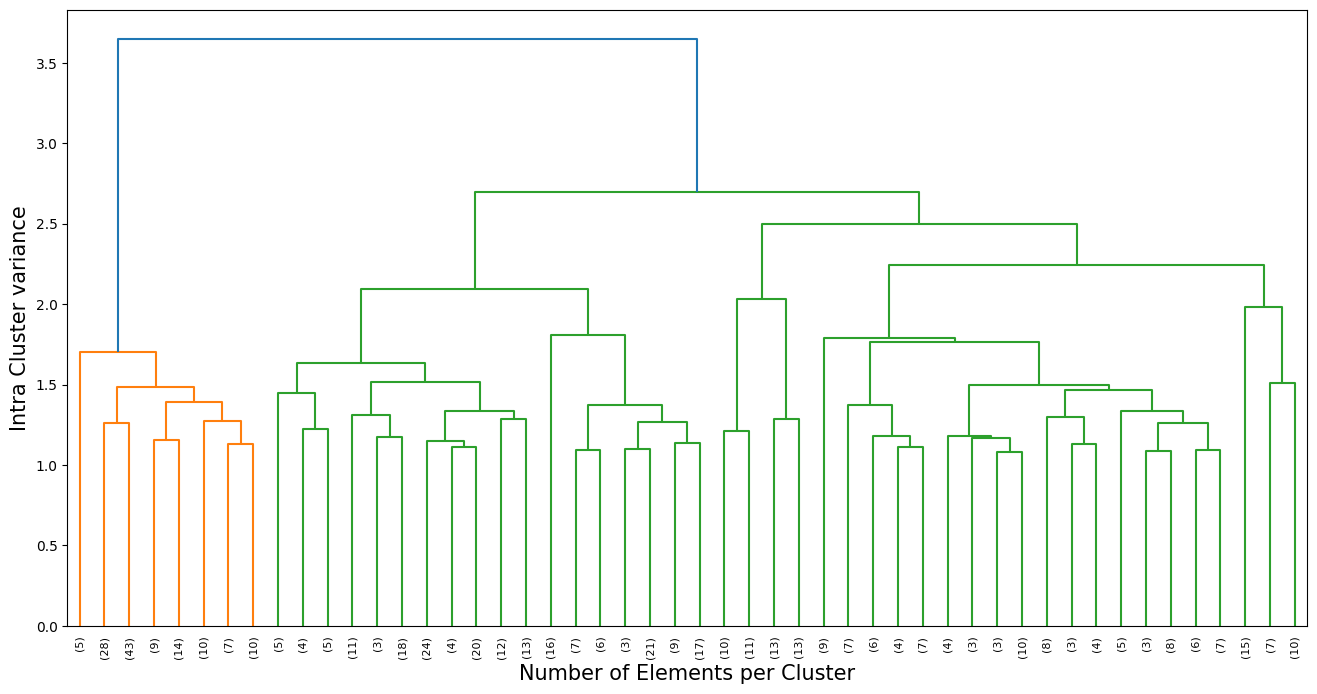

In [68]:
# Load hierarchical clustering
Z = joblib.load('../data/output/hierarchical_cluster_Z.joblib')

# Plot
plt.figure(figsize=(16, 8))
# plt.title("Hierarchical clustering dendrogram")
# dendrogram(Z, truncate_mode='lastp', p=50, leaf_rotation=90, color_threshold=4.96787729660)
dendrogram(Z, truncate_mode='lastp', p=50, leaf_rotation=90, color_threshold=3.3553076382448)
plt.ylabel('Intra Cluster variance', size=15)
plt.xlabel('Number of Elements per Cluster', size=15)
plt.savefig('../data/output/dendrogram.pdf', format='pdf')
plt.show()

In [69]:
# Extract threshold distances for each number of clusters
def get_threshold_distances(Z, k):
    # Extract distances from linkage matrix Z (third column)
    distances = np.sort(Z[:, 2])
    
    # La distancia umbral es la (n-k)-ésima distancia en el dendrograma
    n = Z.shape[0] + 1
    if k >= n:
        return 0  # Si k es igual o mayor al número de muestras, la distancia es mínima
    
    threshold_distance = distances[-(k-1)]
    return threshold_distance

# Rango de clusters deseado
cluster_range = range(3, 51)

# Diccionario para almacenar las distancias umbrales para cada número de clusters
threshold_distances = {k: get_threshold_distances(Z, k) for k in cluster_range}

# Mostrar las distancias umbrales para cada número de clusters
display(threshold_distances)


{3: 2.6952247077001164,
 4: 2.499794527330901,
 5: 2.2454369282396747,
 6: 2.094566860816295,
 7: 2.033163637129854,
 8: 1.9819531562110149,
 9: 1.8050056272363237,
 10: 1.7918064030590417,
 11: 1.7668947495581329,
 12: 1.7025522384910974,
 13: 1.6340606865260034,
 14: 1.51743638019849,
 15: 1.5063550573214421,
 16: 1.4962523851845089,
 17: 1.4837061905960756,
 18: 1.466620153556401,
 19: 1.4445359828315072,
 20: 1.3930002408004136,
 21: 1.3755903121271007,
 22: 1.3706963933260663,
 23: 1.3384006843868417,
 24: 1.3380694040470154,
 25: 1.3099143867196197,
 26: 1.3006752828214359,
 27: 1.2876424630913534,
 28: 1.2830631773014378,
 29: 1.2756623833247474,
 30: 1.2645974631939194,
 31: 1.2619090222989229,
 32: 1.260322947490355,
 33: 1.2209893948637658,
 34: 1.210089329080387,
 35: 1.180077131219846,
 36: 1.1793723198890522,
 37: 1.1737128480104375,
 38: 1.1682660840468886,
 39: 1.158065759519522,
 40: 1.1468475120597426,
 41: 1.1384499174243912,
 42: 1.1277959628079894,
 43: 1.1272191425

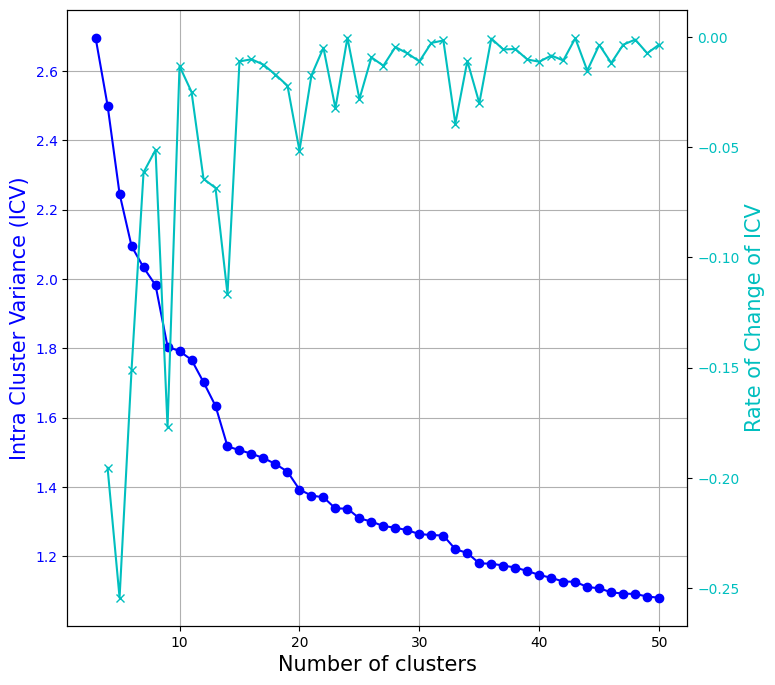

In [70]:
k_range = np.array(list(threshold_distances.keys()))
distances = np.array(list(threshold_distances.values()))
distances_dff = np.diff(distances)

# Create figure
fig, ax1 = plt.subplots(figsize=(8, 8))

# Plot threshold distances
ax1.plot(k_range, distances, marker='o', color='b', label='Threshold Distance')
ax1.set_xlabel('Number of clusters', size=15)
ax1.set_ylabel('Intra Cluster Variance (ICV)', color='b', size=15)
ax1.tick_params(axis='y', labelcolor='b')
ax1.grid(True)

# Plot rate of change of threshold distances
ax2 = ax1.twinx()
ax2.plot(k_range[1:], distances_dff, marker='x', color='c', label='Rate of Change of Threshold Distance')
ax2.set_ylabel('Rate of Change of ICV', color='c', size=15)
ax2.tick_params(axis='y', labelcolor='c')

# Show plot
# plt.title('Threshold Distance and Rate of Change')
plt.savefig('../data/output/elbow_method_hierarchical_clustering.pdf', format='pdf')
plt.show()

In [71]:
# # Tune threshold for level selection for hierarchical conceptual map
# k_list_concpetual_map = k_range[np.where(distances_dff < -0.5)]
# k_list_concpetual_map

In [72]:
# df_cluster = pd.DataFrame()

# df_cluster['clusters_1'] = 0

# for k in k_list_concpetual_map:
#     clusters_HC = fcluster(Z, k, criterion='maxclust') - 1
#     df_cluster[f'clusters_{k}'] = clusters_HC

# df_cluster['clusters_1'] = 0

# df_cluster

In [73]:
# for col_idx, n_clusters in enumerate(df_cluster.columns):
#     for cluster in df_cluster[n_clusters].sort_values().unique():

#         df_topic = df_vectorized_original[df_cluster[n_clusters] == cluster]
#         centroid_words = summarize(df_topic, 5)
#         print(f'Cluster {cluster} ({df_topic.shape[0]}): {centroid_words}')

#         print(f' |---- Cluster {0}')
#     print('-'*100)

Elegir cantidad de tópicos

In [74]:
k = 5
clusters = list(range(k))
print(clusters)

[0, 1, 2, 3, 4]


In [75]:
# Asignar el cluster correspondiente
df['cluster_HC'] = fcluster(Z, k, criterion='maxclust') - 1
print(sorted(df['cluster_HC'].unique()))
df["cluster_HC"].value_counts()

[0, 1, 2, 3, 4]


cluster_HC
1    198
0    126
3     97
2     47
4     32
Name: count, dtype: int64

## Kmeans

### Metodo del codo

In [76]:
# # Listas para almacenar la inercia y el Silhouette Score de cada k
# inertia = []
# silhouette_scores = []

# # Rango de k para probar
# k_range = range(10, 51)  # Puedes cambiar el rango de 1 a 10, o más según necesites

# # Calcular la inercia y el Silhouette Score para cada valor de k
# for k_value in k_range:
#     print(f"Comenzando KMeans para k={k_value}")
#     tic = time.time()

#     kmeans = KMeans(n_clusters=k_value, random_state=0, n_init=100, init='k-means++', max_iter=100)
#     kmeans.fit(X)
    
#     # Almacenar la inercia
#     inertia.append(kmeans.inertia_)
    
#     # Calcular el Silhouette Score y almacenarlo
#     score = silhouette_score(X, kmeans.labels_)
#     silhouette_scores.append(score)
    
                                
#     toc = time.time()
#     print(f"Completado en {toc - tic:.2f} segundos\n")

# # Guardar
# with open('data/output/kmeans_metrics.pkl', 'wb') as f:
#     pickle.dump({'inertia': inertia, 'silhouette_scores': silhouette_scores}, f)

# k_range = range(10, 51)  # Puedes cambiar el rango de 1 a 10, o más según necesites

# # Cargar
# with open('data/output/kmeans_metrics.pkl', 'rb') as f:
#     metrics = pickle.load(f)
# inertia = metrics['inertia']
# silhouette_scores = metrics['silhouette_scores']

# # Calcular la tasa de cambio para la inercia y el Silhouette Score
# delta_inertia = np.diff(inertia)
# delta_silhouette = np.diff(silhouette_scores)

# # Crear una figura con dos subgráficos (lado a lado)
# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# # Graficar la inercia en el primer subgráfico (izquierda)
# ax1.plot(k_range, inertia, marker='o', color='b', label='Inercia')
# ax1.set_xlabel('Número de clusters (k)')
# ax1.set_ylabel('Inercia', color='b')
# ax1.tick_params(axis='y', labelcolor='b')

# # Graficar la tasa de cambio de la inercia en el eje y derecho
# ax1_twin = ax1.twinx()
# ax1_twin.plot(k_range[1:], delta_inertia, marker='x', color='c', label='Tasa de cambio de Inercia')
# ax1_twin.set_ylabel('Tasa de cambio de Inercia', color='c')
# ax1_twin.tick_params(axis='y', labelcolor='c')

# # Título y leyenda para el primer gráfico
# ax1.set_title('Inercia y Tasa de Cambio de Inercia')
# # ax1.legend(loc='best')

# # Graficar el Silhouette Score en el segundo subgráfico (derecha)
# ax2.plot(k_range, silhouette_scores, marker='o', color='g', label='Silhouette Score')
# ax2.set_xlabel('Número de clusters (k)')
# ax2.set_ylabel('Silhouette Score', color='g')
# ax2.tick_params(axis='y', labelcolor='g')

# # Graficar la tasa de cambio del Silhouette Score en el eje y derecho
# ax2_twin = ax2.twinx()
# ax2_twin.plot(k_range[1:], delta_silhouette, marker='x', color='y', label='Tasa de cambio de Silhouette Score')
# ax2_twin.set_ylabel('Tasa de cambio de Silhouette Score', color='y')
# ax2_twin.tick_params(axis='y', labelcolor='y')

# # Título y leyenda para el segundo gráfico
# ax2.set_title('Silhouette Score y Tasa de Cambio de Silhouette Score')
# # ax2.legend(loc='best')

# # Mostrar el gráfico
# plt.tight_layout()  # Ajusta el espacio entre los subgráficos
# plt.show()

### Clustering final

In [77]:
# kmeans = KMeans(n_clusters=k, random_state=0, n_init=100, init='k-means++', max_iter=100).fit(X)
# df["cluster_KM"] = kmeans.predict(X)

# print(sorted(df['cluster_KM'].unique()))
# df["cluster_KM"].value_counts()

Clasificación de un texto

In [78]:
# predicted_cluster = kmeans.predict(topico_vec)
# print(predicted_cluster)

## Results

In [79]:
# Pintar los KNN del topico consultado
# df.loc[indices_knn[0], "cluster_HC"] = -1
# df.loc[indices_knn[0], "cluster_KM"] = -1

Choose clustering type:
* cluster_HC
* cluster_KM

In [80]:
# Select clsutering method
clustering_method = "cluster_HC"

# Convert clsuter column to categorical type
df[clustering_method] = df[clustering_method].astype('category')

In [81]:
# # PCA

# # Calcular centroides de cada cluster
# centroids = df.groupby(clustering_method)[['pca2d_1', 'pca2d_2']].mean().reset_index()

# # Crear gráfico de dispersión interactivo con leyenda discreta
# fig = px.scatter(
#     df, 
#     x='pca2d_1',
#     y='pca2d_2',
#     size=None,
#     color=clustering_method,  # Usar la columna categórica para el color
#     title='PCA 2D',
#     color_discrete_sequence=px.colors.qualitative.Alphabet,  # Usar una paleta de colores discreta
#     hover_data=[clustering_method, 'title'],  # Agregar el cluster y el título al tooltip
#     hover_name='title',  # Mostrar el título como identificador principal en el tooltip
#     opacity=0.5,
#     category_orders={clustering_method: clusters}
# )

# # Asegurar que la relación de aspecto sea 1:1 tanto en los ejes como en la figura
# fig.update_layout(
#     xaxis=dict(scaleanchor="y"),  # Vincula la escala del eje x con el eje y
#     yaxis=dict(scaleanchor="x"),  # Vincula la escala del eje y con el eje x
#     width=800,  # Establece un tamaño específico para el ancho
#     height=600,  # Establece el mismo tamaño para la altura
#     legend_title_text='Cluster'  # Personalizar el título de la leyenda
# )

# # Personalizar el formato del tooltip
# fig.update_traces(
#     marker=dict(size=5),
#     hovertemplate="<b>Title:</b> %{hovertext}<br>" +  # Título en negrita
#                   "<b>Cluster:</b> %{customdata[0]}<br>" +  # Mostrar el cluster (usando customdata)
#                   "<b>X:</b> %{x}<br>" +  # Coordenada X
#                   "<b>Y:</b> %{y}<br>" +  # Coordenada Y
#                   "<extra></extra>"  # Eliminar información adicional no deseada
# )

# # Agregar puntos resaltados en rojo, sin que aparezcan en la leyenda
# fig.add_scatter(
#     x=df.loc[knn_idxs[0], 'pca2d_1'],
#     y=df.loc[knn_idxs[0], 'pca2d_2'],
#     mode='markers',
#     marker=dict(color='red', size=10, line=dict(color='black', width=2)),
#     name='KNNs',
#     showlegend=True,
#     customdata=df.loc[knn_idxs[0], [clustering_method]],  # Asegurar que tengan los mismos datos adicionales
#     hovertext=df.loc[knn_idxs[0], 'title'],  # Usar el título también para estos puntos
#     hovertemplate="<b>Title:</b> %{hovertext}<br>" +
#                   "<b>Cluster:</b> %{customdata[0]}<br>" +
#                   "<b>X:</b> %{x}<br>" +
#                   "<b>Y:</b> %{y}<br>" +
#                   "<extra></extra>"
# )

# # Obtener los colores usados en el gráfico principal
# colors = px.colors.qualitative.Alphabet

# # Crear un diccionario que mapea cada cluster a un color
# cluster_colors = dict(zip(df[clustering_method].cat.categories, colors))

# # Agregar centroides con el color correspondiente de su cluster
# for cluster in centroids[clustering_method]:
#     centroid = centroids[centroids[clustering_method] == cluster]
#     fig.add_scatter(
#         x=centroid['pca2d_1'],
#         y=centroid['pca2d_2'],
#         mode='markers',
#         marker=dict(color=cluster_colors[cluster], size=10, symbol='x', line=dict(color='black', width=2)),
#         name=f'Centroid {cluster}',  # Opcional, si quieres que aparezca en la leyenda
#         showlegend=False
#     )

# # Mostrar el gráfico
# fig.show()

In [82]:
# UMAP 2D

# Calcular centroides de cada cluster
centroids = df.groupby(clustering_method)[['umap2d_1', 'umap2d_2']].mean().reset_index()

custom_colors = [
    "#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd", 
    "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf", "#f6a828"
]

custom_colors = custom_colors[:len(clusters)]

# Crear gráfico de dispersión interactivo
fig = px.scatter(
    df, 
    x='umap2d_1',
    y='umap2d_2',
    size=None,
    color=clustering_method,
    color_discrete_sequence=custom_colors,
    hover_data=[clustering_method, 'title'],
    hover_name='title',
    opacity=0.7,
    category_orders={clustering_method: clusters}
)

# Fondo blanco, grilla visible y ejes definidos
fig.update_layout(
    plot_bgcolor='white',
    paper_bgcolor='white',
    xaxis=dict(
        title='umap2d_1',
        showgrid=True,
        gridcolor='lightgray',
        gridwidth=1,
        zeroline=False,
        scaleanchor="y"
    ),
    yaxis=dict(
        title='umap2d_2',
        showgrid=True,
        gridcolor='lightgray',
        gridwidth=1,
        zeroline=False,
        scaleanchor="x"
    ),
    width=800,
    height=800,
    legend_title_text='Cluster',
    legend_title_font_size=20,  # Tamaño más grande para el título de la leyenda
    legend_font_size=18,        # Tamaño más grande para el texto de la leyenda
    legend_tracegroupgap=10,    # Espaciado entre grupos de leyenda
    legend_traceorder='normal', # Orden normal de leyenda
    legend_itemwidth=30,        # Ancho de los elementos de la leyenda
    legend_itemsizing='constant' # Mantener el tamaño de los símbolos constante
)

# Personalizar el formato del tooltip
fig.update_traces(
    marker=dict(size=10),
    hovertemplate="<b>Title:</b> %{hovertext}<br>" +
                  "<b>Cluster:</b> %{customdata[0]}<br>" +
                  "<b>X:</b> %{x}<br>" +
                  "<b>Y:</b> %{y}<br>" +
                  "<extra></extra>"
)

# Agregar puntos resaltados (KNNs) en rojo
fig.add_scatter(
    x=df.loc[knn_idxs[0], 'umap2d_1'],
    y=df.loc[knn_idxs[0], 'umap2d_2'],
    mode='markers',
    marker=dict(color='red', size=10, line=dict(color='black', width=2)),
    name='KNNs',
    showlegend=True,
    customdata=df.loc[knn_idxs[0], [clustering_method]],
    hovertext=df.loc[knn_idxs[0], 'title'],
    hovertemplate="<b>Title:</b> %{hovertext}<br>" +
                  "<b>Cluster:</b> %{customdata[0]}<br>" +
                  "<b>X:</b> %{x}<br>" +
                  "<b>Y:</b> %{y}<br>" +
                  "<extra></extra>"
)

# Asociar colores a cada cluster
cluster_colors = dict(zip(df[clustering_method].cat.categories, custom_colors))

# Agregar centroides con los colores correspondientes
for cluster in centroids[clustering_method]:
    centroid = centroids[centroids[clustering_method] == cluster]
    fig.add_scatter(
        x=centroid['umap2d_1'],
        y=centroid['umap2d_2'],
        mode='markers',
        marker=dict(color=cluster_colors[cluster], size=12, symbol='x', line=dict(color='black', width=2)),
        name=f'Centroid {cluster}',
        showlegend=False
    )

# Guardar gráfico como PDF
fig.write_image("../data/output/UMAP.pdf")

# Mostrar gráfico
fig.show()

C:\Users\Ingeniería Eléctrica\AppData\Local\Temp\ipykernel_16292\2001953989.py:4: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



# Summarization
Importantest words by Tf-Idf score

In [83]:
def summarize(df_topic, n_centroid_words):

    # Find centroid
    centroid = df_topic.mean(axis=0)

    # Take the n first words
    centroid_words = ", ".join([words[idx] for idx in centroid.argsort()[::-1][:n_centroid_words]])
    
    # To list, remove duplicated words
    centroid_words = centroid_words.replace(',','').split(' ')
    centroid_words_temp = []
    for word in centroid_words:
        if word not in centroid_words_temp:
            centroid_words_temp.append(word)
    centroid_words = centroid_words_temp
    
    return centroid_words

### Corpus

In [84]:
df_topic = df_vectorized_original.copy()
centroid_words = summarize(df_topic, 10)
print(f'Full corpus: {centroid_words}')

# word_cloud(centroid_words)

Full corpus: ['control', 'voltage', 'current', 'converter', 'predictive', 'multilevel', 'model', 'frequency', 'capacitor', 'modular']


### Clusters

In [85]:
for cluster in clusters:
    df_topic = df_vectorized_original[df[clustering_method] == cluster]
    centroid_words = summarize(df_topic, 20)
    print(f'Cluster {cluster}: {", ".join(centroid_words)}')

    # word_cloud(centroid_words)

Cluster 0: control, predictive, voltage, model, current, converter, mpc, multilevel, switching, cost, state, function, modular, capacitor, level, method, strategy, mmc, output, high
Cluster 1: voltage, control, current, converter, capacitor, multilevel, frequency, circulating, mmc, modular, arm, controller, balancing, modulation, dc, power, harmonic, method, high, component
Cluster 2: control, matrix, voltage, frequency, converter, current, low, speed, drive, mode, multilevel, machine, modular, strategy, fluctuation, high, capacitor, predictive, power, model
Cluster 3: control, voltage, current, loop, converter, power, energy, model, closed, dc, strategy, system, multilevel, controller, mmc, ac, modular, state, grid, dynamic
Cluster 4: impedance, control, oscillation, wind, frequency, stability, loop, voltage, current, system, offshore, model, mmc, power, converter, high, matrix, outer, farm, modeling


# Hierarchical conceptual map

In [86]:
# import networkx as nx

# # Crear el grafo dirigido
# G = nx.DiGraph()

# # Ejemplo de títulos y niveles de clusters
# niveles = {
#     0: [],
#     1: ["Cluster A", "Cluster B", "Cluster C"],
#     2: ["Cluster A1", "Cluster A2", "Cluster B1", "Cluster B2", "Cluster C1"]
# }

# # Conectar los niveles de clusters
# relaciones = [
#     ('\n'.join(centroid_words), "Cluster A"),
#     ('\n'.join(centroid_words), "Cluster B"),
#     ('\n'.join(centroid_words), "Cluster C"),
#     ("Cluster A", "Cluster A1"),
#     ("Cluster A", "Cluster A2"),
#     ("Cluster B", "Cluster B1"),
#     ("Cluster B", "Cluster B2"),
#     ("Cluster C", "Cluster C1")
# ]

# # Agregar nodos y aristas al grafo
# for nivel in niveles.values():
#     G.add_nodes_from(nivel)
# G.add_edges_from(relaciones)

# # Asignar posiciones centradas a los nodos
# pos = {}
# max_width = max(len(nodos) for nodos in niveles.values())

# for nivel, nodos in niveles.items():
#     offset = (max_width - len(nodos)) / 2
#     for i, nodo in enumerate(nodos):
#         pos[nodo] = (i + offset, -nivel)

# # Dibujar el mapa conceptual jerárquico
# plt.figure(figsize=(8, 6))
# nx.draw(G, pos, with_labels=True, node_size=3000, node_color='lightblue', font_size=10, font_weight='bold', edge_color='gray')
# plt.title("Mapa Conceptual Jerárquico")
# plt.show()

# Documento representativo
En corpus completo y por clusters

## Centroides

In [87]:
def encontrar_mas_cercano_al_centroide(df_vectorized, data):
    centroide = df_vectorized.mean(axis=0)
    distancias = euclidean_distances(df_vectorized, [centroide])
    indice_mas_cercano = np.argmin(distancias)
    texto_mas_cercano = data.iloc[indice_mas_cercano]['abstract']
    titulo = data.iloc[indice_mas_cercano]['title']
    return titulo, texto_mas_cercano

### Corpus

In [88]:
titulo, texto_mas_cercano = encontrar_mas_cercano_al_centroide(df_vectorized, data)
display(f"Texto mas representativo del corpus:")
display(f"Título: {titulo}")
display(f"Abstract: {texto_mas_cercano}")

'Texto mas representativo del corpus:'

'Título: enhancing control of a 21 level modular multilevel converter through grid based model predictive current control'

'Abstract: the modular multilevel converter mmc has a flexible structure extending the number of voltage levels on the ac side this structure has many advantages such as low switching frequency and a smaller number of transistor valves therefore the mmc converter makes it easy to apply control algorithms and is widely applied to high voltage power grids this paper presents the control method of an mmc converter on the ac side with 10 sub modules sm in each phase to generate 21 voltage levels the process is performed by the current control method based on finite control set model predictive control fcs mpc with the advantage of fast response optimizing the converter s working process by predicting the working states of the converter according to the model the fcs mpc control algorithm has been used in this model the results of the proposed method are proven by using matlab simulink software the results have shown the requirements of the dc ac converter such as sinusoidal current and vol

### Clusters

In [89]:
data.shape

(500, 7)

In [90]:
for cluster in clusters:
    cluster_data_vectorized = df_vectorized.loc[(df[clustering_method] == cluster).values]
    cluster_data = data[df[clustering_method] == cluster]
    titulo, texto_mas_cercano = encontrar_mas_cercano_al_centroide(cluster_data_vectorized, cluster_data)
    display(f"Cluster {cluster}: Texto mas cercano al centroide")
    display(f"Título: {titulo}")
    display(f"Abstract: {texto_mas_cercano}")

'Cluster 0: Texto mas cercano al centroide'

'Título: design and experimental evaluation of fast model predictive control for modular multilevel converters'

'Abstract: in recent years modular multilevel converters mmcs are very popular in medium high voltage motor drive systems and high voltage direct current hvdc applications the conventional model predictive control mpc strategies for the mmc are not practical due to their substantial calculation requirements especially under high number of voltage levels to solve this problem a fast mpc strategy combined with a submodule sm voltage sorting balancing method is proposed based on the discrete mathematical model derived for the mmc in this paper by optimizing the implementation of the control objectives and simplifying the rolling optimization the proposed strategy is simpler to expand to a system with larger number of sms with the amount of calculation reduced and the advantages of the conventional mpc algorithm reserved in addition the proposed control can minimize the dv dt of the output voltages both steady state and transient performances are evaluated by a down scaled three phase mmc 

'Cluster 1: Texto mas cercano al centroide'

'Título: impact of circulating current control in capacitor voltage ripples of modular multilevel converters under grid imbalances'

...

'Título: comparison of current control strategies in modular multilevel converter'

'Abstract: there is a need to transmit the power generated from windfarm in remote locations to the residential and industrial load one of the suitable and economic solution for such long distance transmission of power is the high voltage dc hvdc transmission the modular multilevel converter mmc based hvdc transmission is a proven technology with very high power quality a multi objective control is used to control the mmc one of the objectives is to deliver the power from windfarm to grid the other objective of the control is to achieve stable operation of the mmc in order to achieve a stable operation the capacitors in the mmc should be balanced and the currents circulating within the phases of the mmc need to be controlled many control strategies have been proposed to suppress such circulating current cc however there is no clear comparison between these control strategies in this paper control strategies for the mmc are reviewed specifically the circulating current suppressor the ca

'Cluster 4: Texto mas cercano al centroide'

'Título: the impedance modelling of mmc for oscillation analysis considering control dynamics and delays'

'Abstract: the oscillation phenomena in the modular multilevel converter mmc based hvdc system has caused severe damage to the related devices and grids the fundamental causes of the oscillations can be very sophisticated depending on the configuration and control operation of the system therefore an impedance model of the mmc was proposed while considering the dynamic characteristic of each control loop and the overall signal delays in the control scheme the results have shown that the current inner loop active power control loop and the overall signal delays have great impacts on the impedance characteristics of the converter the impacts of the control loops and the delay times have been demonstrated by deriving the impedance model of the mmc and compared to the measured impedance curve which was obtained by frequency scanning method the consistence between these two curves have proven the accuracy and effectiveness of the proposed impedance model'

## Puntaje Tfidf
Le llamaremos representante al abstract que tenga una mayor cantidad de frecuencia acumulada de palabras del tfid vectorizer, ya que eso implica una mayor participación (profundizar).

Disclaimer: Tenía razón en dudad del método. esto en verdad lo k hace es elegir al que tiene mayor interaccion entre palabras, es decir, el abstract mas complejo.

### Corpus

In [91]:
abstract00 = df_vectorized.sum(axis=1).sort_values(ascending=False).index[0]
display("Texto más representativo del corpus:")
display(f"Título: {data['title'].iloc[abstract00]}")
display(f"Abstract: {data['abstract'].iloc[abstract00]}")

'Texto más representativo del corpus:'

'Título: model predictive control of a statcom based on a modular multilevel converter in delta configuration'

'Abstract: this paper proposes a model predictive control mpc scheme for the single delta bridge cell sdbc modular multilevel converter mmc when operated as a static synchronous compensator statcom the controller achieves reactive power compensation and current harmonic elimination while maintaining the branch currents and capacitor voltages within their safe operating limits the mpc scheme manipulates the setpoints of a subsequent pulse width modulator pwm the controller is conceptually simple with an easy to devise objective function a linearized converter model based on first principles and constraints on the main physical quantities the underlying optimization problem is a quadratic program qp which can be solved efficiently using off the shelf solvers the developed control framework achieves a good performance at steady state operation and very fast current response during load transients'

### Clusters

In [92]:
for cluster in clusters:
    abstract00 = df_vectorized.loc[(df[clustering_method] == cluster).values].sum(axis=1).sort_values(ascending=False).index[0]
    df_topic = df_vectorized_original[df[clustering_method] == cluster]
    centroid_words = summarize(df_topic, 10)
    display(f"Cluster {cluster}: {centroid_words}")
    display(f"Título: {data['title'].iloc[abstract00]}")
    display(f"Abstract: {data['abstract'].iloc[abstract00]}")

"Cluster 0: ['control', 'predictive', 'voltage', 'model', 'current', 'converter', 'mpc', 'multilevel', 'switching', 'cost']"

'Título: model predictive control of a statcom based on a modular multilevel converter in delta configuration'

'Abstract: this paper proposes a model predictive control mpc scheme for the single delta bridge cell sdbc modular multilevel converter mmc when operated as a static synchronous compensator statcom the controller achieves reactive power compensation and current harmonic elimination while maintaining the branch currents and capacitor voltages within their safe operating limits the mpc scheme manipulates the setpoints of a subsequent pulse width modulator pwm the controller is conceptually simple with an easy to devise objective function a linearized converter model based on first principles and constraints on the main physical quantities the underlying optimization problem is a quadratic program qp which can be solved efficiently using off the shelf solvers the developed control framework achieves a good performance at steady state operation and very fast current response during load transients'

"Cluster 1: ['voltage', 'control', 'current', 'converter', 'capacitor', 'multilevel', 'frequency', 'circulating', 'mmc', 'modular']"

'Título: pseudo derivative feedback circulating current suppression controller for modular multilevel converter with flying capacitor submodules'

...

'Título: an extended level model predictive control method with reduced current thd for modular multilevel converter battery energy storage system'

'Abstract: the modular multilevel converter battery energy storage system mmc bess is a converter system with the potential to enhance grid reliability however the implementation of model predictive control mpc in mmc bess is confronted with challenges such as substantial computational demands suboptimal quality of output current and challenges in selecting weighting factors to address these challenges this paper puts forward an extended level mpc approach which involves the direct calculation of the output voltage reference value in the load mpc stage followed by the optimization of the output level through a step by step optimization method additionally it employs a cost function that optimizes the current area to further reduce the total harmonic distortion thd notably this process ensures a computational complexity of 5 for each control cycle independent of the number of sub modules two control strategies are employed to optimize the circulating current control depending on the num

"Cluster 4: ['impedance', 'control', 'oscillation', 'wind', 'frequency', 'stability', 'loop', 'voltage', 'current', 'system']"

'Título: modeling and control of mmc based hvdc system with analysis of its internal and external dynamics'

'Abstract: this paper presents an enhanced control technique for modular multilevel converters mmcs in high voltage direct current hvdc transmission systems the mathematical models of an mmc are developed based on its circuit configuration operation and dynamics a power decoupled method using vector control is proposed to regulate the active and reactive power flow from the hvdc mmc system to the grid due to the large number of submodules sms in mmcs circulating currents may arise from voltage mismatches between sm capacitors to address this a combination of voltage balancing mechanisms with phase shift pulse width modulation ps pwm is introduced to improve mmc dynamics circulating current suppression control is achieved without separating the positive and negative dq components ensuring fast response of the inner current mechanism time domain simulations are conducted to validate the proposed control method while the results demonstrate good controllability and reliability of the prop

## Similaridad del coseno

### Corpus

In [93]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def RepresentanteCoseno(matrix_vectors):
    """
    Retorna el índice del texto más representativo del conjunto (más similar al resto).
    
    Parameters:
    - matrix_vectors: matriz (numpy array o pandas DataFrame) donde cada fila es un vector (TF-IDF o embedding)
    
    Returns:
    - Índice del texto más representativo
    """
    # Asegura que sea array de NumPy
    if hasattr(matrix_vectors, 'values'):
        matrix_vectors = matrix_vectors.values

    # Calcular matriz de similitud coseno
    similitudes = cosine_similarity(matrix_vectors)
    
    # Sumar similitudes por fila (suma de cada vector con todos los demás)
    suma_similitudes = np.sum(similitudes, axis=1)
    
    # Retornar índice del vector con mayor similitud total
    return np.argmax(suma_similitudes)


In [94]:
abstract00 = RepresentanteCoseno(df_vectorized)
titulo = data["title"].iloc[abstract00]
abstract_mas_representativo = data["abstract"].iloc[abstract00]

display(f"Texto mas similar a todos los demas en el corpus:")
display(f"Título: {titulo}")
display(f"Abstract: {abstract_mas_representativo}")

'Texto mas similar a todos los demas en el corpus:'

'Título: enhancing control of a 21 level modular multilevel converter through grid based model predictive current control'

'Abstract: the modular multilevel converter mmc has a flexible structure extending the number of voltage levels on the ac side this structure has many advantages such as low switching frequency and a smaller number of transistor valves therefore the mmc converter makes it easy to apply control algorithms and is widely applied to high voltage power grids this paper presents the control method of an mmc converter on the ac side with 10 sub modules sm in each phase to generate 21 voltage levels the process is performed by the current control method based on finite control set model predictive control fcs mpc with the advantage of fast response optimizing the converter s working process by predicting the working states of the converter according to the model the fcs mpc control algorithm has been used in this model the results of the proposed method are proven by using matlab simulink software the results have shown the requirements of the dc ac converter such as sinusoidal current and vol

### Clusters

In [95]:
for cluster in clusters:
    abstract00 = RepresentanteCoseno(df_vectorized.loc[(df[clustering_method] == cluster).values])
    titulo = data["title"].iloc[abstract00]
    abstract_mas_representativo = data["abstract"].iloc[abstract00]
    df_topic = df_vectorized_original[df[clustering_method] == cluster]
    centroid_words = summarize(df_topic, 10)
    display(f"Cluster {cluster}: {centroid_words}")
    display(f"Título: {titulo}")
    display(f"Abstract: {abstract_mas_representativo}")

"Cluster 0: ['control', 'predictive', 'voltage', 'model', 'current', 'converter', 'mpc', 'multilevel', 'switching', 'cost']"

'Título: research on coordinated control strategy of modular multilevel converter system'

'Abstract: at present with the continuous popularization of green energy the modular multilevel converter system is widely used there are many control strategies for the mmc system in recent years some new control methods and ideas have been proposed while most of them are optimized and improved on the basis of general control strategies such as pi control master slave control and model predictive control therefore this paper based on the basic wiring mode of the multi terminal flexible dc transmission system and proposes an optimized control strategy for network power flow optimization for verifying the reliability of the control strategy proposed in this paper based on the matlab simulink a seven terminal system simulation model was built on which can compare the general droop control and the optimized model predictive control simulation the simulation results of a calculation example ensure the reliability of the control strategy the anti oscillation coefficient characteristic curve

"Cluster 1: ['voltage', 'control', 'current', 'converter', 'capacitor', 'multilevel', 'frequency', 'circulating', 'mmc', 'modular']"

'Título: finite control set model predictive control of an active nested neutral point clamped converter'

...

'Título: mpc based current and local cluster balancing controls for low frequency ac transmission systems'

'Abstract: this work proposes an model predictive control mpc strategy applied to modular multilevel matrix converter m3c for low frequency ac lfac transmission systems the novelty of the proposal is the use of a current and local cluster balancing lcb control based on mpc for a lfac transmission system which is composed by at least one grid forming and grid following control for m3cs as a results the mpc based strategy allows to control cluster currents and to regulate the local and cluster energies with low capacitor voltage ripple and operate at low frequency while generating a low frequency grid and extracting injecting power from the lfac system simulations are presented to validate the proposed strategy for both m3cs the first m3c generates the low frequency voltage grid and the second m3c transfers power from one side to the other'

"Cluster 4: ['impedance', 'control', 'oscillation', 'wind', 'frequency', 'stability', 'loop', 'voltage', 'current', 'system']"

'Título: experimental comparison of model predictive control and cascaded control of the modular multilevel converter'

'Abstract: this paper evaluates two different concepts for the control of the modular multilevel converter mmc generally aiming at medium voltage applications the considered mmc topology has a low number of submodules and a pulse width modulation pwm scheme is applied a model predictive control mpc algorithm is developed and experimentally compared to a cascaded control scheme based on conventional pi controllers which has been proposed by hagiwara and akagi steady state and dynamic system performance as well as computational power requirements are discussed the basis for the comparison is a scaled converter test bench operating from 560 v dc voltage'

# Grafo de palabras

## Palabras de un abstract especifico

In [96]:
# # Obtener el texto del dataframe
# texto = df.iloc[1000]["abstract"]

# # Procesar el texto con spaCy
# doc = nlp(texto)

# # Crear grafo dirigido con NetworkX
# G = nx.DiGraph()
# for token in doc:
#     if not token.is_stop and not token.is_punct:
#         G.add_node(token.text)
#     for child in token.children:
#         if not child.is_stop and not child.is_punct:
#             G.add_edge(token.text, child.text)

# # Calcular importancia con PageRank
# pagerank = nx.pagerank(G)

# # Crear el grafo con Graphviz
# dot = Digraph(format="png")
# dot.attr(dpi="300", rankdir="LR", bgcolor="white")

# # Agregar nodos con tamaño basado en PageRank
# max_pr = max(pagerank.values()) if pagerank else 1
# for node, pr in pagerank.items():
#     size = str(int(10 + (pr / max_pr) * 30))  # Tamaño proporcional
#     dot.node(node, fontsize=size, shape="ellipse", style="filled", fillcolor="lightblue")

# # Agregar aristas
# for u, v in G.edges():
#     dot.edge(u, v, color="black", penwidth="1.5")

# # Renderizar el grafo en un archivo temporal
# output_file = "Data/Figuras/grafo"
# dot.render(output_file, format="png", cleanup=True)
# # Mostrar la imagen en Jupyter Notebook
# display(Image(filename=output_file + ".png"))

## Entre clusters